# Работа с MNIST
***Крюков Антон, КТбо2-5***

# Ход работы:

**1. Импорт библиотек и указание путей к данным**

In [1]:
import struct
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train_images_path = "/content/sample_data/train-images.idx3-ubyte"
train_labels_path = "/content/sample_data/train-labels.idx1-ubyte"
test_images_path = "/content/sample_data/t10k-images.idx3-ubyte"
test_labels_path = "/content/sample_data/t10k-labels.idx1-ubyte"

file_paths = [
    train_images_path,
    train_labels_path,
    test_images_path,
    test_labels_path
]

for file_path in file_paths:
    try:
        with open(file_path, "rb"):
            print("Файл найден:", file_path)
    except FileNotFoundError:
        print("Файл не найден:", file_path)

Файл найден: /content/sample_data/train-images.idx3-ubyte
Файл найден: /content/sample_data/train-labels.idx1-ubyte
Файл найден: /content/sample_data/t10k-images.idx3-ubyte
Файл найден: /content/sample_data/t10k-labels.idx1-ubyte


Импортировали библиотеки для работы с данными и изображениями. Указали пути к обучающим и тестовым файлам MNIST. Проверка показала, что все четыре файла находятся в папке sample_data и доступны для дальнейшей обработки.

**2. Загрузка изображений и меток из файлов IDX**

In [2]:
def load_images(file_path):
    with open(file_path, "rb") as file:
        magic_number, number, rows, columns = struct.unpack(
            ">IIII", file.read(16)
        )

        images = np.frombuffer(file.read(), dtype=np.uint8)
        images = images.reshape(number, rows, columns)

    return images


def load_labels(file_path):
    with open(file_path, "rb") as file:
        magic_number, number = struct.unpack(
            ">II", file.read(8)
        )

        labels = np.frombuffer(file.read(), dtype=np.uint8)

    return labels


train_images = load_images(train_images_path)
train_labels = load_labels(train_labels_path)

test_images = load_images(test_images_path)
test_labels = load_labels(test_labels_path)

print("Размер обучающих изображений:", train_images.shape)
print("Размер обучающих меток:", train_labels.shape)
print("Размер тестовых изображений:", test_images.shape)
print("Размер тестовых меток:", test_labels.shape)

Размер обучающих изображений: (60000, 28, 28)
Размер обучающих меток: (60000,)
Размер тестовых изображений: (10000, 28, 28)
Размер тестовых меток: (10000,)


Для чтения файлов IDX создали две функции: первая загружает изображения, а вторая - метки классов. В обучающей выборке содержится 60000 изображений размером 28×28 пикселей и 60000 соответствующих меток. Тестовая выборка содержит 10000 изображений и 10000 меток. Количество изображений совпадает с количеством меток, следовательно данные загружены корректно.

**3. Просмотр примеров изображений**

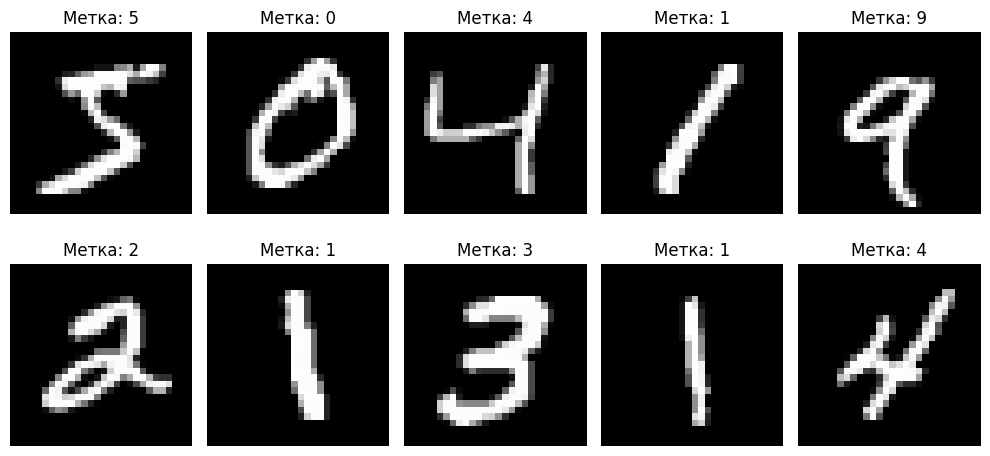

In [3]:
plt.figure(figsize=(10, 5))

for index in range(10):
    plt.subplot(2, 5, index + 1)
    plt.imshow(train_images[index], cmap="gray")
    plt.title("Метка: " + str(train_labels[index]))
    plt.axis("off")

plt.tight_layout()
plt.show()

Вывели первые десять изображений обучающей выборки. На изображениях представлены рукописные цифры на чёрном фоне, а над каждым изображением указана его метка. Метки соответствуют изображённым цифрам, поэтому изображения и классы были загружены правильно.

**4. Анализ распределения классов**

Цифра 0 - 5923 изображений
Цифра 1 - 6742 изображений
Цифра 2 - 5958 изображений
Цифра 3 - 6131 изображений
Цифра 4 - 5842 изображений
Цифра 5 - 5421 изображений
Цифра 6 - 5918 изображений
Цифра 7 - 6265 изображений
Цифра 8 - 5851 изображений
Цифра 9 - 5949 изображений


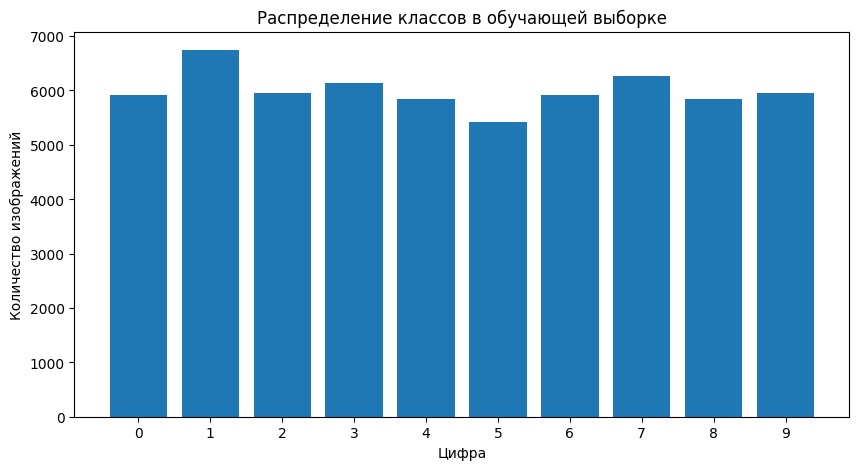

In [4]:
class_counts = np.bincount(train_labels)

for digit in range(10):
    print("Цифра", digit, "-", class_counts[digit], "изображений")

plt.figure(figsize=(10, 5))
plt.bar(range(10), class_counts)

plt.title("Распределение классов в обучающей выборке")
plt.xlabel("Цифра")
plt.ylabel("Количество изображений")
plt.xticks(range(10))

plt.show()

В обучающей выборке видим все десять классов - от 0 до 9. Больше всего изображений относится к цифре 1, а меньше всего к цифре 5. Различия между классами есть, но они не являются критическими. Этот небольшой дисбаланс учитем при расчёте метрик и дальнейшем выборе порогов классификации.

**5. Преобразование изображений в таблицу признаков**

In [5]:
X = train_images.reshape(60000, 784)
y = train_labels

X_test = test_images.reshape(10000, 784)
y_test = test_labels

print("Размер обучающих признаков:", X.shape)
print("Размер обучающих меток:", y.shape)

print("Размер тестовых признаков:", X_test.shape)
print("Размер тестовых меток:", y_test.shape)

print("Минимальное значение пикселя:", X.min())
print("Максимальное значение пикселя:", X.max())

Размер обучающих признаков: (60000, 784)
Размер обучающих меток: (60000,)
Размер тестовых признаков: (10000, 784)
Размер тестовых меток: (10000,)
Минимальное значение пикселя: 0
Максимальное значение пикселя: 255


Каждое изображение размером 28×28 пикселей было преобразовано в строку из 784 признаков. Обучающая таблица содержит 60000 строк, а тестовая - 10000 строк. Значения пикселей находятся в диапазоне от 0 до 255: значение 0 соответствует чёрному цвету, а 255 белому. Получается что, информация об изображениях при преобразовании не была потеряна.

**6. Подключение LightGBM и кросс-валидации**

In [6]:
import lightgbm as lgb

from sklearn.model_selection import StratifiedKFold

print("Версия LightGBM:", lgb.__version__)

Версия LightGBM: 4.6.0


Подключили библиотеку LightGBM для обучения модели. Импортировали инструмент StratifiedKFold, для выполнения кросс-валидации с сохранением распределения десяти классов в каждой части данных.

**7. Обучение LightGBM с кросс-валидацией и ранней остановкой**

In [7]:
from sklearn.metrics import accuracy_score

cross_validation = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

models = []
fold_scores = []
best_iterations = []

oof_probabilities = np.zeros((len(X), 10))

for fold_number, (train_index, valid_index) in enumerate(
    cross_validation.split(X, y),
    start=1
):
    print("Обучение части", fold_number)

    X_train_fold = X[train_index]
    y_train_fold = y[train_index]

    X_valid_fold = X[valid_index]
    y_valid_fold = y[valid_index]

    model = lgb.LGBMClassifier(
        objective="multiclass",
        num_class=10,
        n_estimators=500,
        learning_rate=0.1,
        num_leaves=31,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_train_fold,
        y_train_fold,
        eval_set=[(X_valid_fold, y_valid_fold)],
        eval_metric="multi_logloss",
        callbacks=[
            lgb.early_stopping(stopping_rounds=20),
            lgb.log_evaluation(period=0)
        ]
    )

    valid_probabilities = model.predict_proba(X_valid_fold)
    valid_predictions = np.argmax(valid_probabilities, axis=1)

    oof_probabilities[valid_index] = valid_probabilities

    fold_accuracy = accuracy_score(
        y_valid_fold,
        valid_predictions
    )

    models.append(model)
    fold_scores.append(fold_accuracy)
    best_iterations.append(model.best_iteration_)

    print(
        "Accuracy части",
        fold_number,
        ":",
        round(fold_accuracy, 4)
    )
    print("Лучшая итерация:", model.best_iteration_)
    print()

print(
    "Средняя accuracy:",
    round(np.mean(fold_scores), 4)
)

Обучение части 1
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[137]	valid_0's multi_logloss: 0.0796195


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Accuracy части 1 : 0.9765
Лучшая итерация: 137

Обучение части 2
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[141]	valid_0's multi_logloss: 0.0782364


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Accuracy части 2 : 0.9772
Лучшая итерация: 141

Обучение части 3
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[120]	valid_0's multi_logloss: 0.0917676


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Accuracy части 3 : 0.9742
Лучшая итерация: 120

Средняя accuracy: 0.976


Модель LightGBM была обучена с использованием стратифицированной кросс-валидации из трёх частей. Accuracy на отдельных частях составила 97,65%, 97,72% и 97,42%, а среднее значение - 97,60%. Результаты трёх частей близки друг к другу, поэтому модель работает устойчиво. Ранняя остановка завершила обучение на 137-й, 141-й и 120-й итерациях вместо максимально заданных 500 итераций, это позволило остановить обучение после прекращения улучшения результата и уменьшить риск переобучения.

**8. Расчёт основных метрик качества**

In [8]:
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score
)

oof_predictions = np.argmax(oof_probabilities, axis=1)

auc = roc_auc_score(
    y,
    oof_probabilities,
    multi_class="ovr",
    average="macro"
)

f1 = f1_score(
    y,
    oof_predictions,
    average="macro"
)

precision = precision_score(
    y,
    oof_predictions,
    average="macro"
)

recall = recall_score(
    y,
    oof_predictions,
    average="macro"
)

print("AUC:", round(auc, 4))
print("F1:", round(f1, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

AUC: 0.9995
F1: 0.9759
Precision: 0.9758
Recall: 0.9759


Среднее значение AUC для десяти классов составило 0,9995, это показывает высокую способность модели отделять каждый класс от остальных. Значения F1, precision и recall составили примерно 0,976. Следовательно, модель правильно распознаёт большую часть изображений и показывает сбалансированное качество по разным классам. Macro-усреднение учитывает каждый класс одинаково, поэтому классы с большим количеством изображений не оказывают чрезмерного влияния на результат.

**9. Построение матрицы ошибок**

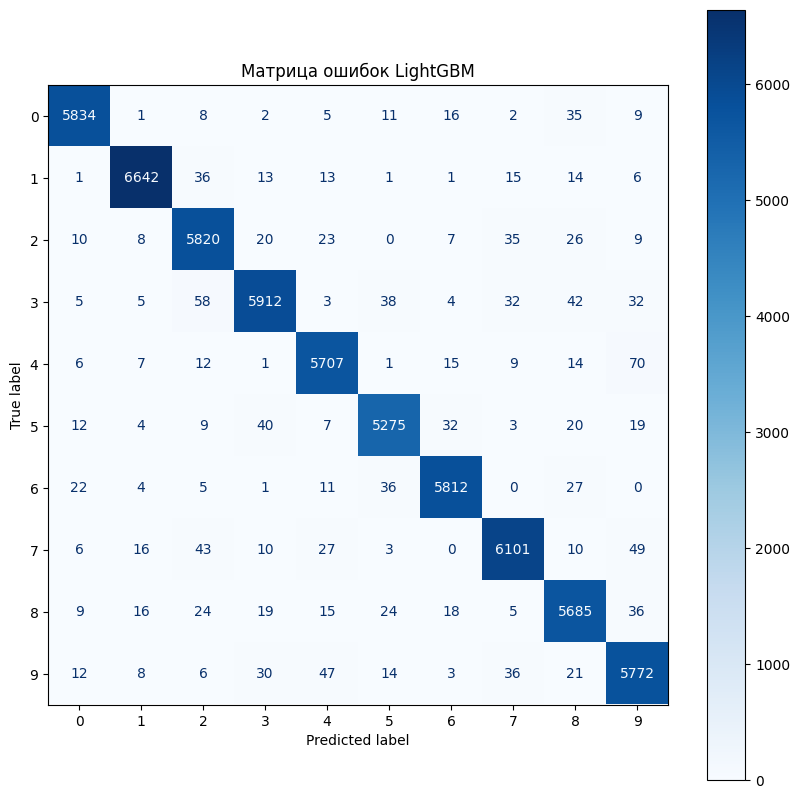

In [9]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

confusion_matrix_result = confusion_matrix(
    y,
    oof_predictions
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix_result,
    display_labels=range(10)
)

figure, axis = plt.subplots(figsize=(10, 10))

display_matrix.plot(
    cmap="Blues",
    values_format="d",
    ax=axis
)

plt.title("Матрица ошибок LightGBM")
plt.show()

Большинство изображений классифицировано правильно. Наиболее заметные ошибки связаны с визуально похожими цифрами: цифра 4 была принята за 9 в 70 случаях, цифра 3 за 2 в 58 случаях, цифра 7 за 9 в 49 случаях, а цифра 9 за 4 в 47 случаях. По сравнению с общим количеством изображений число таких ошибок немного, это подтверждает высокое качество модели.

**10. Построение ROC-кривых**

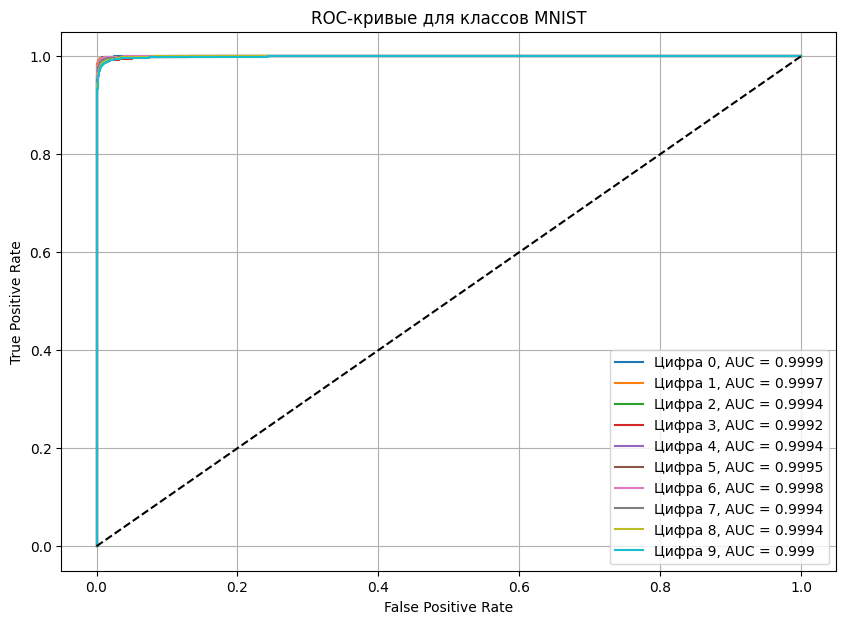

In [10]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve

y_binary = label_binarize(
    y,
    classes=range(10)
)

plt.figure(figsize=(10, 7))

for digit in range(10):
    false_positive_rate, true_positive_rate, thresholds = roc_curve(
        y_binary[:, digit],
        oof_probabilities[:, digit]
    )

    class_auc = roc_auc_score(
        y_binary[:, digit],
        oof_probabilities[:, digit]
    )

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        label="Цифра " + str(digit) +
              ", AUC = " + str(round(class_auc, 4))
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black"
)

plt.title("ROC-кривые для классов MNIST")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

ROC-кривые расположены около левого верхнего угла, выше пунктирной линии случайного классификатора. Значения AUC находятся от 0,9990 до 0,9999. Это означает, что модель хорошо отделяет изображения каждой цифры от изображений остальных классов. Наибольшее значение AUC получено для цифры 0, а наименьшее для цифры 9, но качество для всех классов остаётся высоким.

**11. Построение Precision-Recall-кривых**

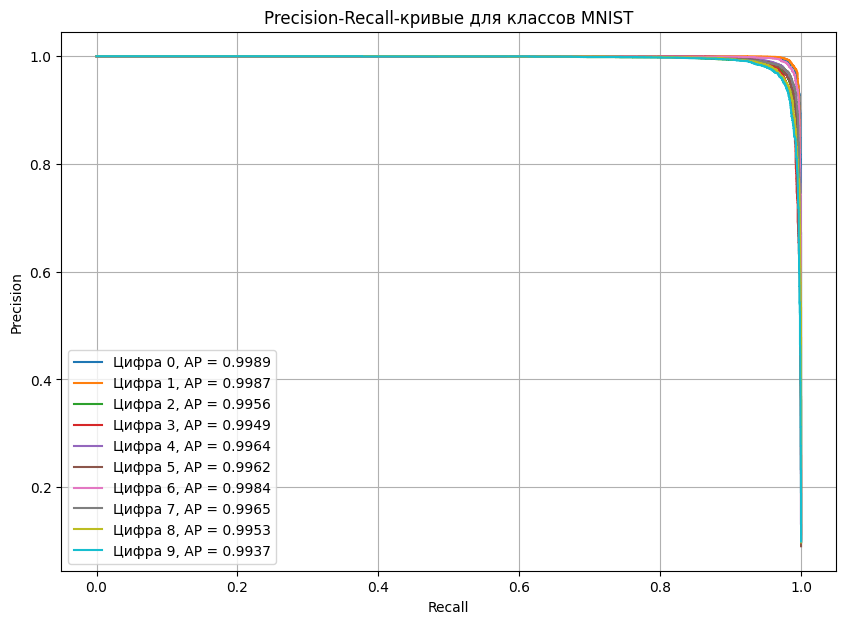

In [11]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

plt.figure(figsize=(10, 7))

for digit in range(10):
    precision_values, recall_values, thresholds = (
        precision_recall_curve(
            y_binary[:, digit],
            oof_probabilities[:, digit]
        )
    )

    average_precision = average_precision_score(
        y_binary[:, digit],
        oof_probabilities[:, digit]
    )

    plt.plot(
        recall_values,
        precision_values,
        label="Цифра " + str(digit) +
              ", AP = " + str(round(average_precision, 4))
    )

plt.title("Precision-Recall-кривые для классов MNIST")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid()
plt.show()

Precision-Recall-кривые расположены близко к верхней границе графика, поэтому модель сохраняет высокую точность даже при большом значении полноты. Значение Average Precision находится в диапазоне от 0,9937 до 0,9989. Лучший результат получен для цифры 0, а наиболее сложным классом оказалась цифра 9. При этом качество распознавания всех десяти классов остаётся высоким.

**12. Выбор порогов классификации**

In [12]:
best_thresholds = np.zeros(10)

for digit in range(10):
    precision_values, recall_values, thresholds = (
        precision_recall_curve(
            y_binary[:, digit],
            oof_probabilities[:, digit]
        )
    )

    f1_values = (
        2 * precision_values[:-1] * recall_values[:-1]
        / (
            precision_values[:-1]
            + recall_values[:-1]
            + 0.000001
        )
    )

    best_index = np.argmax(f1_values)
    best_threshold = thresholds[best_index]

    best_thresholds[digit] = best_threshold

    print(
        "Цифра",
        digit,
        "- лучший порог:",
        round(best_threshold, 4),
        "- F1:",
        round(f1_values[best_index], 4)
    )

Цифра 0 - лучший порог: 0.6753 - F1: 0.9865
Цифра 1 - лучший порог: 0.6176 - F1: 0.9879
Цифра 2 - лучший порог: 0.4515 - F1: 0.9733
Цифра 3 - лучший порог: 0.4315 - F1: 0.9719
Цифра 4 - лучший порог: 0.6347 - F1: 0.9775
Цифра 5 - лучший порог: 0.49 - F1: 0.9752
Цифра 6 - лучший порог: 0.5342 - F1: 0.9834
Цифра 7 - лучший порог: 0.4193 - F1: 0.9767
Цифра 8 - лучший порог: 0.5673 - F1: 0.97
Цифра 9 - лучший порог: 0.535 - F1: 0.9675


Для каждого класса выбрали отдельный порог, при котором достигается максимальное значение F1. Пороги отличаются, так как классы имеют разное количество изображений и разную сложность распознавания. Наибольший порог получен для цифры 0 - 0,6753, а наименьший для цифры 7 —-0,4193. Лучшее значение F1 получено для цифры 1 - 0,9879, а наименьшее для цифры 9 - 0,9675.

**13. Применение выбранных порогов к тестовой выборке**

In [13]:
test_probabilities = np.zeros((len(X_test), 10))

for model in models:
    test_probabilities += model.predict_proba(X_test)

test_probabilities = test_probabilities / len(models)

default_test_predictions = np.argmax(
    test_probabilities,
    axis=1
)

threshold_test_predictions = []

for probabilities in test_probabilities:
    passed_classes = np.where(
        probabilities >= best_thresholds
    )[0]

    if len(passed_classes) == 0:
        predicted_class = np.argmax(probabilities)
    else:
        predicted_class = passed_classes[
            np.argmax(probabilities[passed_classes])
        ]

    threshold_test_predictions.append(predicted_class)

threshold_test_predictions = np.array(
    threshold_test_predictions
)

default_f1 = f1_score(
    y_test,
    default_test_predictions,
    average="macro"
)

threshold_f1 = f1_score(
    y_test,
    threshold_test_predictions,
    average="macro"
)

print(
    "F1 без выбранных порогов:",
    round(default_f1, 4)
)

print(
    "F1 с выбранными порогами:",
    round(threshold_f1, 4)
)

changed_predictions = np.sum(
    default_test_predictions
    != threshold_test_predictions
)

print(
    "Количество изменённых предсказаний:",
    changed_predictions
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


F1 без выбранных порогов: 0.9787
F1 с выбранными порогами: 0.9787
Количество изменённых предсказаний: 4


Изменились только 4 предсказания из 10000. Значение F1 осталось равным 0,9787. Это из-за небольшого дисбалансом классов и высокой уверенностью модели в большинстве предсказаний. Таким образом, подбор порогов не ухудшил качество, но его влияние на данном датасете оказалось минимальным. Дальше при оценке будем использовать предсказания с выбранными порогами.

**14. Оценка модели на тестовой выборке**

In [14]:
test_accuracy = accuracy_score(
    y_test,
    threshold_test_predictions
)

test_auc = roc_auc_score(
    y_test,
    test_probabilities,
    multi_class="ovr",
    average="macro"
)

test_f1 = f1_score(
    y_test,
    threshold_test_predictions,
    average="macro"
)

test_precision = precision_score(
    y_test,
    threshold_test_predictions,
    average="macro"
)

test_recall = recall_score(
    y_test,
    threshold_test_predictions,
    average="macro"
)

print("Accuracy:", round(test_accuracy, 4))
print("AUC:", round(test_auc, 4))
print("F1:", round(test_f1, 4))
print("Precision:", round(test_precision, 4))
print("Recall:", round(test_recall, 4))

Accuracy: 0.9788
AUC: 0.9997
F1: 0.9787
Precision: 0.9787
Recall: 0.9786


На тестовой выборке accuracy составила 0,9788, то есть модель правильно распознала около 97,88% изображений. Значение AUC равно 0,9997, а F1, precision и recall составили примерно 0,979. Результаты на тестовой выборке близки к результатам кросс-валидации, поэтому модель хорошо работает на новых изображениях и не показывает заметного переобучения.

**15. Расчёт SHAP-значений**

In [15]:
import shap

best_model_index = np.argmax(fold_scores)
shap_model = models[best_model_index]

np.random.seed(42)

shap_indices = np.random.choice(
    len(X),
    size=500,
    replace=False
)

shap_data = X[shap_indices]
shap_labels = y[shap_indices]

explainer = shap.TreeExplainer(shap_model)
shap_values = explainer.shap_values(shap_data)

print(
    "Для SHAP выбрана модель части:",
    best_model_index + 1
)

print(
    "Размер выборки для SHAP:",
    shap_data.shape
)

print(
    "Размер SHAP-значений:",
    np.array(shap_values).shape
)

Для SHAP выбрана модель части: 2
Размер выборки для SHAP: (500, 784)
Размер SHAP-значений: (500, 784, 10)


Выбрали модель второй части кросс-валидации, поскольку она показала наибольшую accuracy. SHAP-значения рассчитаны для 500 случайных изображений. Каждое изображение содержит 784 пикселя, а для каждого пикселя получено влияние на все 10 классов. Поэтому размер массива SHAP составляет 500×784×10.

**16. Построение SHAP summary plot**

/tmp/ipykernel_649/3753303430.py:21: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


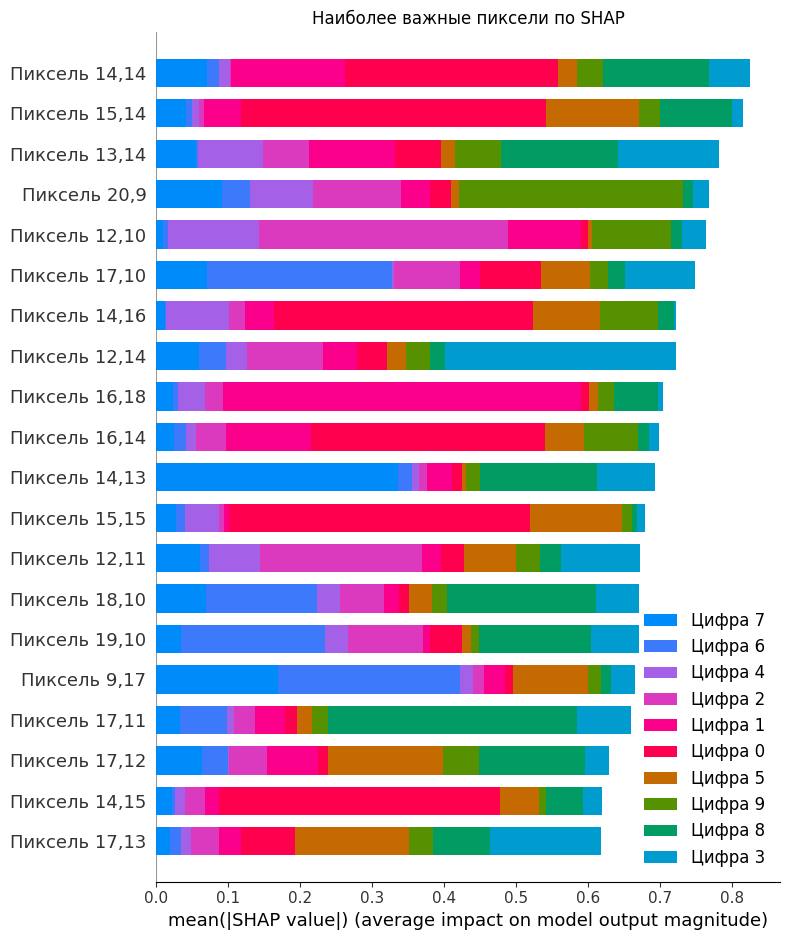

In [16]:
feature_names = []

for row in range(28):
    for column in range(28):
        feature_names.append(
            "Пиксель " + str(row) + "," + str(column)
        )

shap_values_by_class = []

for digit in range(10):
    shap_values_by_class.append(
        shap_values[:, :, digit]
    )

class_names = []

for digit in range(10):
    class_names.append("Цифра " + str(digit))

shap.summary_plot(
    shap_values_by_class,
    shap_data,
    feature_names=feature_names,
    class_names=class_names,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title("Наиболее важные пиксели по SHAP")
plt.tight_layout()
plt.show()

 Изображения MNIST выровнены по центру и основные линии цифр обычно проходят через эту область. Разные цвета показывают вклад пикселей в распознавание разных цифр.

**17. Локальные объяснения предсказаний с помощью SHAP**

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


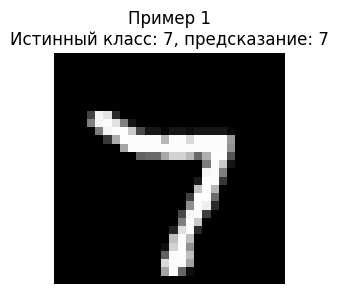

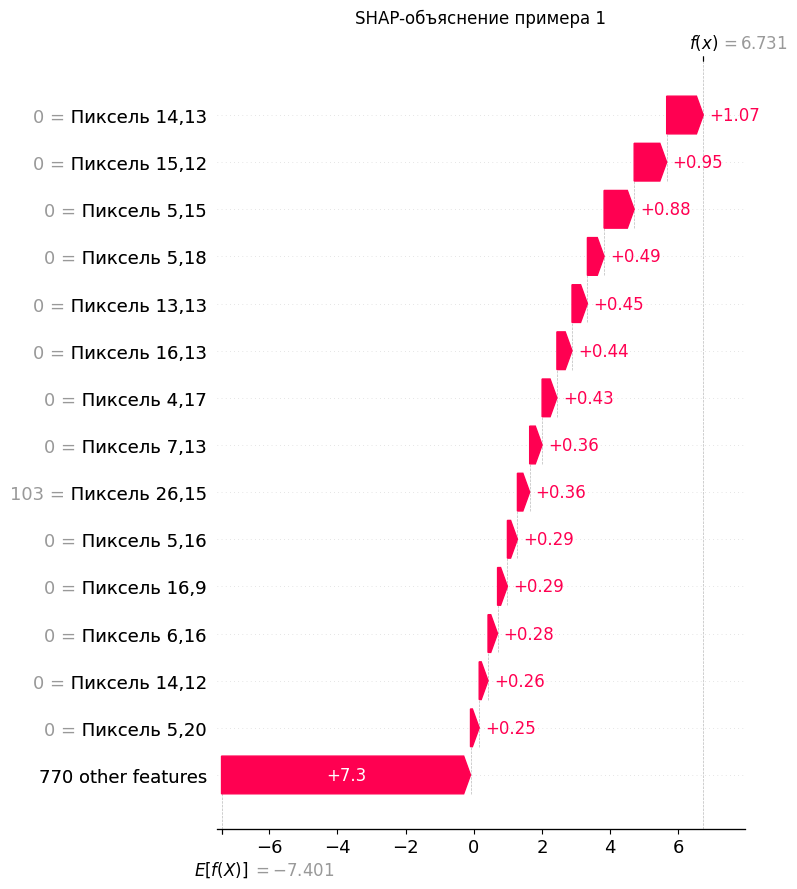

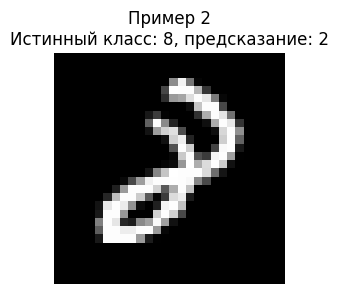

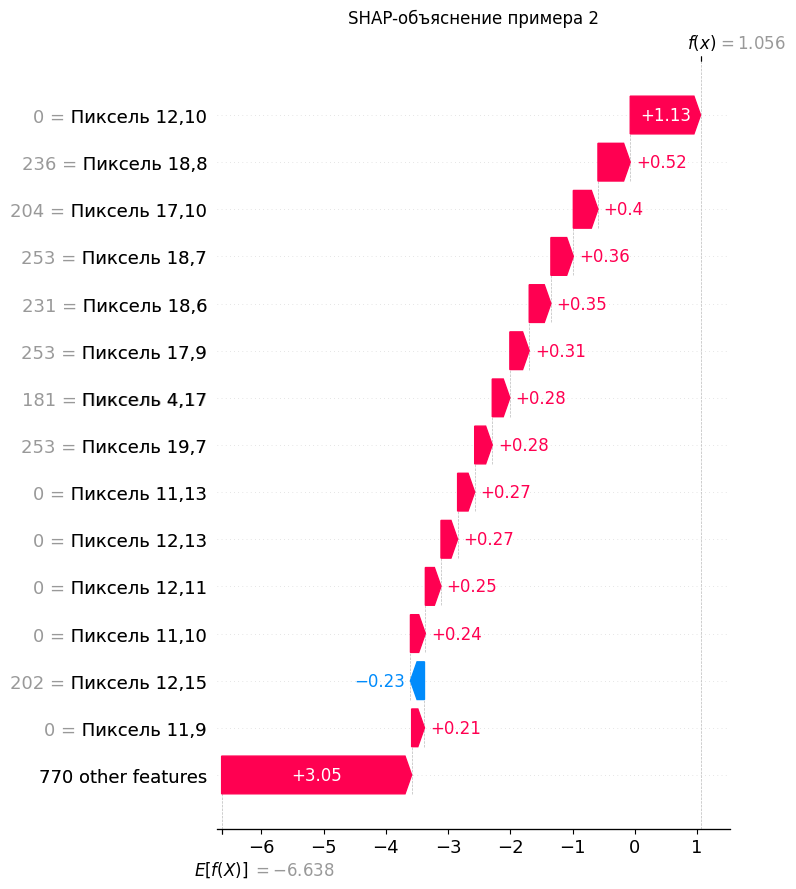

In [17]:
shap_predictions = shap_model.predict(shap_data)

correct_indices = np.where(
    shap_predictions == shap_labels
)[0]

wrong_indices = np.where(
    shap_predictions != shap_labels
)[0]

example_indices = [correct_indices[0]]

if len(wrong_indices) > 0:
    example_indices.append(wrong_indices[0])
else:
    example_indices.append(correct_indices[1])

for example_number, example_index in enumerate(
    example_indices,
    start=1
):
    true_class = int(shap_labels[example_index])
    predicted_class = int(
        shap_predictions[example_index]
    )

    plt.figure(figsize=(3, 3))
    plt.imshow(
        shap_data[example_index].reshape(28, 28),
        cmap="gray"
    )
    plt.title(
        "Пример " + str(example_number)
        + "\nИстинный класс: " + str(true_class)
        + ", предсказание: " + str(predicted_class)
    )
    plt.axis("off")
    plt.show()

    local_explanation = shap.Explanation(
        values=shap_values[
            example_index,
            :,
            predicted_class
        ],
        base_values=explainer.expected_value[
            predicted_class
        ],
        data=shap_data[example_index],
        feature_names=feature_names
    )

    shap.plots.waterfall(
        local_explanation,
        max_display=15,
        show=False
    )

    plt.title(
        "SHAP-объяснение примера "
        + str(example_number)
    )
    plt.tight_layout()
    plt.show()

В первом примере цифра 7, модель правильно определила класс 7. SHAP-график показывает, что совокупность пикселей увеличила оценку этого класса до 6,731. Наибольшее положительное влияние оказали пиксели 14,13; 15,12 и 5,15.

Во втором примере цифра 8, но модель предсказала цифру 2. По форме изображение  похоже на цифру 2: верхняя и нижняя части восьмёрки не полностью замкнуты. Пиксели в центральной и нижней части изображения увеличили оценку класса 2, из-за чего модель допустила ошибку. Этот пример показывает, что SHAP позволяет определить, какие части изображения повлияли на конкретное решение модели.

**18. Сохранение обученной модели**

In [18]:
import joblib

model_data = {
    "models": models,
    "thresholds": best_thresholds
}

model_path = "/content/mnist_lightgbm_model.pkl"

joblib.dump(
    model_data,
    model_path
)

print("Модель сохранена:", model_path)

Модель сохранена: /content/mnist_lightgbm_model.pkl


Обученные модели кросс-валидации и выбранные пороги классификации были сохранены.

**19. Подготовка изображений и CSV-файлов**

In [19]:
import os

from PIL import Image

train_directory = "/content/mnist_data/train"
test_directory = "/content/mnist_data/test"

os.makedirs(train_directory, exist_ok=True)
os.makedirs(test_directory, exist_ok=True)

train_records = []

for index in range(len(train_images)):
    image_path = (
        train_directory
        + "/train_"
        + str(index)
        + ".png"
    )

    Image.fromarray(
        train_images[index]
    ).save(image_path)

    train_records.append({
        "image_path": image_path,
        "label": int(train_labels[index])
    })

    if (index + 1) % 10000 == 0:
        print(
            "Сохранено обучающих изображений:",
            index + 1
        )

test_records = []

for index in range(len(test_images)):
    image_path = (
        test_directory
        + "/test_"
        + str(index)
        + ".png"
    )

    Image.fromarray(
        test_images[index]
    ).save(image_path)

    test_records.append({
        "image_path": image_path,
        "label": int(test_labels[index])
    })

    if (index + 1) % 10000 == 0:
        print(
            "Сохранено тестовых изображений:",
            index + 1
        )

train_csv = pd.DataFrame(train_records)
test_ground_truth_csv = pd.DataFrame(test_records)

test_input_csv = test_ground_truth_csv[
    ["image_path"]
].copy()

train_csv.to_csv(
    "/content/ground_truth_train.csv",
    index=False
)

test_ground_truth_csv.to_csv(
    "/content/ground_truth_test.csv",
    index=False
)

test_input_csv.to_csv(
    "/content/input_test.csv",
    index=False
)

print()
print("Обучающий CSV:", train_csv.shape)
print(
    "Тестовый CSV с метками:",
    test_ground_truth_csv.shape
)
print(
    "Входной CSV без меток:",
    test_input_csv.shape
)

Сохранено обучающих изображений: 10000
Сохранено обучающих изображений: 20000
Сохранено обучающих изображений: 30000
Сохранено обучающих изображений: 40000
Сохранено обучающих изображений: 50000
Сохранено обучающих изображений: 60000
Сохранено тестовых изображений: 10000

Обучающий CSV: (60000, 2)
Тестовый CSV с метками: (10000, 2)
Входной CSV без меток: (10000, 1)


Из файлов IDX были извлечены 60000 обучающих и 10000 тестовых изображений. Изображения сохранены в формате PNG. Также были созданы три CSV-файла: обучающий файл с путями и метками, тестовый файл с правильными метками и входной файл без меток для режима инференса.

**20. Создание основного скрипта mnist.py**

In [20]:
%%writefile /content/mnist.py

import argparse
import joblib

import numpy as np
import pandas as pd
import lightgbm as lgb

from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_recall_curve
)

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import label_binarize


def load_images(csv_path):
    data = pd.read_csv(csv_path)

    images = []

    for image_path in data["image_path"]:
        image = Image.open(image_path).convert("L")
        image = image.resize((28, 28))

        image_array = np.array(
            image,
            dtype=np.uint8
        )

        images.append(
            image_array.reshape(784)
        )

    images = np.array(images)

    return data, images


def select_thresholds(labels, probabilities):
    binary_labels = label_binarize(
        labels,
        classes=range(10)
    )

    thresholds_result = np.zeros(10)

    for digit in range(10):
        precision, recall, thresholds = (
            precision_recall_curve(
                binary_labels[:, digit],
                probabilities[:, digit]
            )
        )

        f1_values = (
            2 * precision[:-1] * recall[:-1]
            / (
                precision[:-1]
                + recall[:-1]
                + 0.000001
            )
        )

        best_index = np.argmax(f1_values)

        thresholds_result[digit] = (
            thresholds[best_index]
        )

    return thresholds_result


def predict_with_thresholds(
    probabilities,
    thresholds
):
    predictions = []

    for image_probabilities in probabilities:
        passed_classes = np.where(
            image_probabilities >= thresholds
        )[0]

        if len(passed_classes) == 0:
            predicted_class = np.argmax(
                image_probabilities
            )
        else:
            predicted_class = passed_classes[
                np.argmax(
                    image_probabilities[
                        passed_classes
                    ]
                )
            ]

        predictions.append(predicted_class)

    return np.array(predictions)


def train_model(dataset_path, model_path):
    data, images = load_images(dataset_path)

    if "label" not in data.columns:
        raise ValueError(
            "В обучающем CSV отсутствует столбец label"
        )

    labels = data["label"].to_numpy()

    cross_validation = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    models = []
    fold_scores = []

    oof_probabilities = np.zeros(
        (len(images), 10)
    )

    for fold_number, (
        train_index,
        valid_index
    ) in enumerate(
        cross_validation.split(
            images,
            labels
        ),
        start=1
    ):
        print(
            "Обучение части",
            fold_number
        )

        X_train = images[train_index]
        y_train = labels[train_index]

        X_valid = images[valid_index]
        y_valid = labels[valid_index]

        model = lgb.LGBMClassifier(
            objective="multiclass",
            num_class=10,
            n_estimators=500,
            learning_rate=0.1,
            num_leaves=31,
            random_state=42,
            n_jobs=-1,
            verbosity=-1
        )

        model.fit(
            X_train,
            y_train,
            eval_set=[
                (X_valid, y_valid)
            ],
            eval_metric="multi_logloss",
            callbacks=[
                lgb.early_stopping(
                    stopping_rounds=20
                ),
                lgb.log_evaluation(
                    period=0
                )
            ]
        )

        valid_probabilities = (
            model.predict_proba(X_valid)
        )

        valid_predictions = np.argmax(
            valid_probabilities,
            axis=1
        )

        oof_probabilities[
            valid_index
        ] = valid_probabilities

        fold_accuracy = accuracy_score(
            y_valid,
            valid_predictions
        )

        models.append(model)
        fold_scores.append(fold_accuracy)

        print(
            "Accuracy части:",
            round(fold_accuracy, 4)
        )
        print(
            "Лучшая итерация:",
            model.best_iteration_
        )
        print()

    thresholds = select_thresholds(
        labels,
        oof_probabilities
    )

    model_data = {
        "models": models,
        "thresholds": thresholds
    }

    joblib.dump(
        model_data,
        model_path
    )

    print(
        "Средняя accuracy:",
        round(np.mean(fold_scores), 4)
    )
    print(
        "Модель сохранена:",
        model_path
    )


def run_inference(
    model_path,
    input_path,
    output_path
):
    model_data = joblib.load(model_path)

    models = model_data["models"]
    thresholds = model_data["thresholds"]

    input_data, images = load_images(
        input_path
    )

    probabilities = np.zeros(
        (len(images), 10)
    )

    for model in models:
        probabilities += model.predict_proba(
            images
        )

    probabilities = (
        probabilities / len(models)
    )

    predictions = predict_with_thresholds(
        probabilities,
        thresholds
    )

    result = pd.DataFrame({
        "image_path": input_data[
            "image_path"
        ],
        "label": predictions
    })

    result.to_csv(
        output_path,
        index=False
    )

    print(
        "Обработано изображений:",
        len(result)
    )
    print(
        "Предсказания сохранены:",
        output_path
    )


parser = argparse.ArgumentParser()

parser.add_argument(
    "--mode",
    required=True,
    choices=["train", "inference"]
)

parser.add_argument("--dataset")
parser.add_argument("--model", required=True)
parser.add_argument("--input")
parser.add_argument("--output")

arguments = parser.parse_args()


if arguments.mode == "train":
    if arguments.dataset is None:
        raise ValueError(
            "Не указан параметр --dataset"
        )

    train_model(
        arguments.dataset,
        arguments.model
    )


if arguments.mode == "inference":
    if arguments.input is None:
        raise ValueError(
            "Не указан параметр --input"
        )

    if arguments.output is None:
        raise ValueError(
            "Не указан параметр --output"
        )

    run_inference(
        arguments.model,
        arguments.input,
        arguments.output
    )

Writing /content/mnist.py


Создали скрипт mnist.py с интерфейсом командной строки. В режиме train скрипт загружает обучающий CSV, выполняет кросс-валидацию с ранней остановкой, выбирает пороги и сохраняет модель. В режиме inference скрипт загружает сохранённую модель, обрабатывает изображения из входного CSV и сохраняет полученные метки в отдельный файл.

**21. Создание скрипта оценки evaluate.py**

In [21]:
%%writefile /content/evaluate.py

import argparse

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix
)


parser = argparse.ArgumentParser()

parser.add_argument(
    "--ground-truth",
    required=True
)

parser.add_argument(
    "--predictions",
    required=True
)

arguments = parser.parse_args()


ground_truth = pd.read_csv(
    arguments.ground_truth
)

predictions = pd.read_csv(
    arguments.predictions
)


if "image_path" not in ground_truth.columns:
    raise ValueError(
        "В ground truth отсутствует столбец image_path"
    )

if "label" not in ground_truth.columns:
    raise ValueError(
        "В ground truth отсутствует столбец label"
    )

if "image_path" not in predictions.columns:
    raise ValueError(
        "В predictions отсутствует столбец image_path"
    )

if "label" not in predictions.columns:
    raise ValueError(
        "В predictions отсутствует столбец label"
    )


comparison = ground_truth.merge(
    predictions,
    on="image_path",
    suffixes=("_true", "_pred")
)


accuracy = accuracy_score(
    comparison["label_true"],
    comparison["label_pred"]
)

matrix = confusion_matrix(
    comparison["label_true"],
    comparison["label_pred"]
)


print(
    "Количество сравнённых изображений:",
    len(comparison)
)

print(
    "Accuracy:",
    round(accuracy, 4)
)

print()
print("Confusion Matrix:")
print(matrix)

Writing /content/evaluate.py


Создали скрипт evaluate.py. Он принимает CSV с правильными метками и CSV с предсказаниями, сопоставляет изображения по их путям, рассчитывает accuracy и выводит матрицу ошибок.

**22. Запуск скрипта в режиме инференса**

In [22]:
!python /content/mnist.py \
    --mode inference \
    --model /content/mnist_lightgbm_model.pkl \
    --input /content/input_test.csv \
    --output /content/predictions.csv

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
Обработано изображений: 10000
Предсказания сохранены: /content/predictions.csv


Скрипт mnist.py был запущен в режиме inference. Он успешно загрузил сохранённую модель, обработал 10 000 тестовых изображений и записал полученные метки в файл predictions.csv. Появившиеся предупреждения связаны с отсутствием текстовых названий у пиксельных признаков и не влияют на предсказания.

**23. Оценка сохранённых предсказаний**

In [23]:
!python /content/evaluate.py \
    --ground-truth /content/ground_truth_test.csv \
    --predictions /content/predictions.csv

Количество сравнённых изображений: 10000
Accuracy: 0.9788

Confusion Matrix:
[[ 969    0    0    0    0    2    3    1    4    1]
 [   0 1125    3    1    0    1    1    1    3    0]
 [   3    0 1008    6    2    0    0    6    7    0]
 [   0    0    2  989    0    4    0    8    4    3]
 [   0    0    4    0  962    0    4    0    2   10]
 [   2    0    1    7    0  869    5    4    2    2]
 [   6    2    0    0    3    4  938    0    5    0]
 [   2    2   15    3    1    0    0  998    2    5]
 [   4    0    3    0    1    3    3    3  951    6]
 [   6    5    1    5    6    1    0    4    2  979]]


Скрипт сравнил все 10000 тестовых изображений. Accuracy составила 0,9788, поэтому правильно классифицировано около 97,88% тестовой выборки. Основные значения расположены на главной диагонали матрицы. Наиболее заметные ошибки связаны с похожими цифрами. В целом количество ошибок невелико.

**24. Проверка созданных скриптов**

In [24]:
!python -m py_compile /content/mnist.py
!python -m py_compile /content/evaluate.py

print("Синтаксис скриптов проверен")

!python /content/mnist.py --help

Синтаксис скриптов проверен
usage: mnist.py [-h] --mode {train,inference} [--dataset DATASET]
                --model MODEL [--input INPUT] [--output OUTPUT]

options:
  -h, --help            show this help message and exit
  --mode {train,inference}
  --dataset DATASET
  --model MODEL
  --input INPUT
  --output OUTPUT


Синтаксис файлов mnist.py и evaluate.py был успешно проверен. Основной скрипт поддерживает два режима работы: train и inference, а также принимает пути к датасету, модели, входному и выходному CSV-файлам.

# Вывод:

В ходе работы был построен пайплайн классификации изображений MNIST с помощью LightGBM. Данные содержали 60000 обучающих и 10000 тестовых изображений размером 28×28 пикселей. Модель обучалась с использованием стратифицированной кросс-валидации из трёх частей и ранней остановки. Средняя accuracy при кросс-валидации составила 0,9760.

На тестовой выборке accuracy составила 0,9788, AUC - 0,9997, F1 - 0,9787, precision - 0,9787, recall - 0,9786. ROC- и Precision-Recall-кривые показали высокое качество распознавания всех десяти классов.

Для каждого класса был выбран отдельный порог классификации. После применения порогов изменились только 4 предсказания, а значение F1 осталось прежним. Это связано с небольшим дисбалансом классов и высокой уверенностью модели.

С помощью SHAP были определены наиболее важные пиксели и рассмотрены два локальных примера. Основное влияние на предсказания оказывают пиксели центральной части изображения. Ошибочный пример показал, что модель может путать визуально похожие цифры.

В дальнейшем качество модели можно улучшить, если подобрать более подходящие настройки LightGBM и использовать больше частей при кросс-валидации. Также можно создать дополнительные варианты изображений, немного поворачивая или сдвигая цифры. Ещё один вариант - использовать нейронную сеть, которая лучше подходит для распознавания изображений.

**25. Сохранение файлов работы**

In [27]:
import zipfile

from google.colab import files

archive_path = (
    "/content/MNIST_KryukovAA_KTbo2_5_files.zip"
)

files_to_save = [
    "/content/mnist.py",
    "/content/evaluate.py",
    "/content/mnist_lightgbm_model.pkl",
    "/content/predictions.csv",
    "/content/ground_truth_test.csv",
    "/content/input_test.csv",
    "/content/ground_truth_train.csv"
]

with zipfile.ZipFile(
    archive_path,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:
    for file_path in files_to_save:
        archive.write(
            file_path,
            arcname=file_path.split("/")[-1]
        )

print("Архив создан:", archive_path)

files.download(archive_path)

Архив создан: /content/MNIST_KryukovAA_KTbo2_5_files.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>